In [ ]:
print("Firewall Log Anomaly Detector")
print("Practical implementation started successfully.")

Firewall Log Anomaly Detector
Practical implementation started successfully.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
np.random.seed(42)
n_normal = 5000
n_anomalies = 250
normal_data = pd.DataFrame({
    "src_port": np.random.randint(1024, 50000, n_normal),

    "dst_port": np.random.choice(
        [80, 443, 22, 53, 25, 110, 143],
        n_normal ),
    "protocol": np.random.choice(
        ["TCP", "UDP"],
        n_normal,
        p=[0.75, 0.25]  ),

    "duration": np.random.exponential(
        2,
        n_normal  ),

    "packets": np.random.poisson(
        20,
        n_normal  ),

    "bytes": np.random.normal(
        5000,
        1500,
        n_normal  ),

    "failed_connections": np.random.poisson(
        0.2,
        n_normal    ),

    "connection_rate": np.random.normal(
        5,
        1.5,
        n_normal )
})
normal_data["bytes"] = normal_data["bytes"].clip(lower=100)
anomaly_data = pd.DataFrame({
    "src_port": np.random.randint(
        1,
        65535,
        n_anomalies  ),

    "dst_port": np.random.choice(
        [21, 23, 445, 3389, 4444, 5555, 8080, 9999],
        n_anomalies  ),

    "protocol": np.random.choice(
        ["TCP", "UDP"],
        n_anomalies ),

    "duration": np.random.uniform(
        30,
        300,
        n_anomalies ),

    "packets": np.random.randint(
        200,
        2000,
        n_anomalies ),

    "bytes": np.random.randint(
        50000,
        1000000,
        n_anomalies  ),

    "failed_connections": np.random.randint(
        5,
        100,
        n_anomalies  ),

    "connection_rate": np.random.uniform(
        50,
        500,
        n_anomalies  )
})

df = pd.concat(
    [normal_data, anomaly_data],
    ignore_index=True
)
df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Firewall dataset created successfully!")
print()
print(f"Normal traffic records   : {n_normal}")
print(f"Anomalous records        : {n_anomalies}")
print(f"Total records            : {len(df)}")

Firewall dataset created successfully!

Normal traffic records   : 5000
Anomalous records        : 250
Total records            : 5250


In [ ]:
def generate_ip():
    return ".".join(
        str(np.random.randint(1, 255))
        for _ in range(4)
    )
df["src_ip"] = [
    generate_ip()
    for _ in range(len(df))
]

df["dst_ip"] = [
    generate_ip()
    for _ in range(len(df))
]

df["timestamp"] = pd.date_range(
    start="2026-01-01",
    periods=len(df),
    freq="min"
)

df = df[
    [
        "timestamp",
        "src_ip",
        "dst_ip",
        "src_port",
        "dst_port",
        "protocol",
        "duration",
        "packets",
        "bytes",
        "failed_connections",
        "connection_rate"
    ]
]


print("Firewall log information added successfully!")
print(f"Number of records: {len(df)}")

Firewall log information added successfully!
Number of records: 5250


In [ ]:
df.head(10)

,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,duration,packets,bytes,failed_connections,connection_rate
0,2026-01-01 00:00:00,222.18.13.14,137.247.32.72,22816,22,TCP,0.777311,12,7709.963375,0,4.963247
1,2026-01-01 00:01:00,41.40.249.89,151.27.42.8,27213,143,TCP,4.515295,21,5867.563682,0,5.683014
2,2026-01-01 00:02:00,101.219.215.199,221.11.149.243,1364,110,UDP,2.190574,16,5155.006333,0,4.812960
3,2026-01-01 00:03:00,48.10.217.121,44.167.222.33,49543,143,UDP,0.618634,26,4853.359653,0,6.721246
4,2026-01-01 00:04:00,54.163.152.49,67.55.13.36,35075,25,TCP,1.489982,18,4294.237692,1,4.927919
5,2026-01-01 00:05:00,170.203.84.202,87.26.202.38,22986,110,UDP,3.423835,13,3401.409897,0,4.106809
6,2026-01-01 00:06:00,50.149.156.220,100.151.136.14,45044,25,TCP,0.409792,15,6404.356552,0,5.229848
7,2026-01-01 00:07:00,183.155.97.68,24.119.210.168,28504,110,TCP,0.107840,18,3807.715868,0,4.846795
8,2026-01-01 00:08:00,99.84.134.186,101.238.153.118,3787,22,TCP,4.731212,21,4604.929477,0,5.785476
9,2026-01-01 00:09:00,134.60.81.147,239.212.153.17,39583,53,TCP,3.469887,16,5081.534292,0,7.710393


In [ ]:
print("Dataset dimensions:")
print(df.shape)

Dataset dimensions:
(5250, 11)


In [ ]:
print("Dataset information:")
print()

df.info()

Dataset information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   timestamp           5250 non-null   datetime64[ns]
 1   src_ip              5250 non-null   object        
 2   dst_ip              5250 non-null   object        
 3   src_port            5250 non-null   int64         
 4   dst_port            5250 non-null   int64         
 5   protocol            5250 non-null   object        
 6   duration            5250 non-null   float64       
 7   packets             5250 non-null   int64         
 8   bytes               5250 non-null   float64       
 9   failed_connections  5250 non-null   int64         
 10  connection_rate     5250 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(4), object(3)
memory usage: 451.3+ KB


In [ ]:
print("Missing values in each column:")
print()

print(df.isnull().sum())

Missing values in each column:

timestamp             0
src_ip                0
dst_ip                0
src_port              0
dst_port              0
protocol              0
duration              0
packets               0
bytes                 0
failed_connections    0
connection_rate       0
dtype: int64


In [ ]:
print("Statistical Summary:")
print()

df.describe()

Statistical Summary:



,timestamp,src_port,dst_port,duration,packets,bytes,failed_connections,connection_rate
count,5250,5250.000000,5250.000000,5250.000000,5250.000000,5250.000000,5250.000000,5250.000000
mean,2026-01-02 19:44:29.999999744,25613.363429,311.328571,9.995322,69.970476,30882.192112,2.732000,18.073478
min,2026-01-01 00:00:00,176.000000,21.000000,0.000237,6.000000,100.000000,0.000000,-0.325254
25%,2026-01-01 21:52:15,13030.000000,25.000000,0.625741,17.000000,4033.713471,0.000000,4.076985
50%,2026-01-02 19:44:30,25446.000000,80.000000,1.507544,20.000000,5093.563425,0.000000,5.124671
75%,2026-01-03 17:36:45,37757.000000,143.000000,3.114911,24.000000,6204.772532,0.000000,6.188946
max,2026-01-04 15:29:00,65335.000000,9999.000000,299.871055,1987.000000,988054.000000,99.000000,496.296645
std,NaN,14428.608721,1120.321295,39.703705,250.401978,129601.340248,12.683448,65.018888


In [ ]:
df["connection_rate"] = df["connection_rate"].clip(lower=0)

print("Connection rate corrected successfully.")
print(f"Minimum connection rate: {df['connection_rate'].min():.2f}")

Connection rate corrected successfully.
Minimum connection rate: 0.00


In [ ]:
print("Protocol distribution:")
print()

print(df["protocol"].value_counts())

Protocol distribution:

protocol
TCP    3903
UDP    1347
Name: count, dtype: int64


In [ ]:
print("Most common destination ports:")
print()

print(
    df["dst_port"].value_counts().head(15)
)

Most common destination ports:

dst_port
443     766
143     744
25      725
110     712
53      698
22      689
80      666
4444     37
21       34
5555     34
8080     33
445      32
23       29
9999     27
3389     24
Name: count, dtype: int64


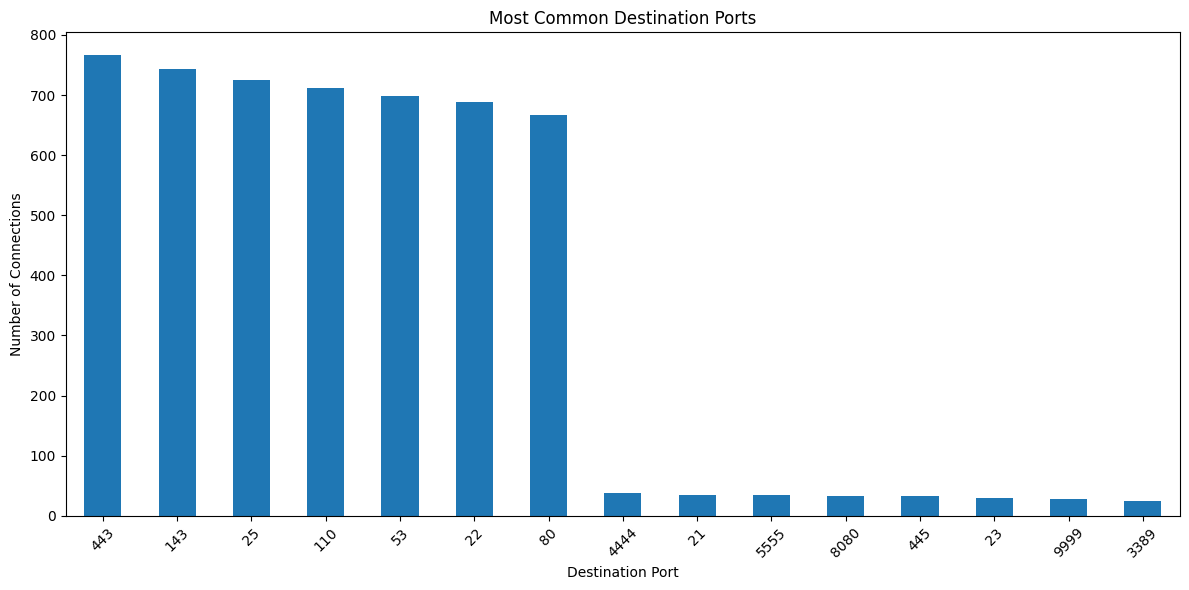

In [ ]:
port_counts = df["dst_port"].value_counts().head(15)
plt.figure(figsize=(12, 6))
port_counts.plot( kind="bar")
plt.title("Most Common Destination Ports")
plt.xlabel("Destination Port")
plt.ylabel("Number of Connections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

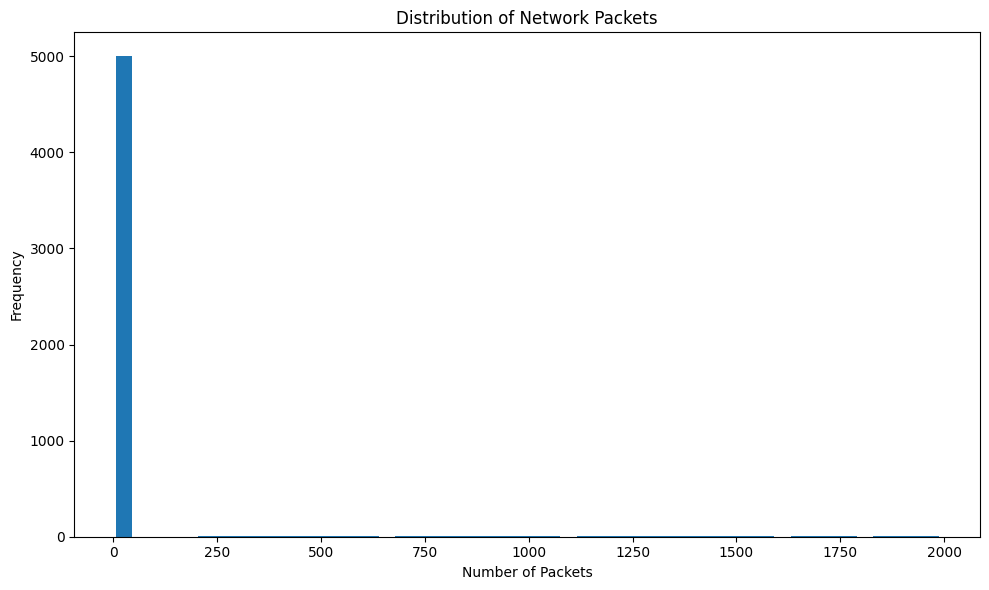

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist( df["packets"],
    bins=50)
plt.title("Distribution of Network Packets")
plt.xlabel("Number of Packets")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
df["hour"] = df["timestamp"].dt.hour
df["bytes_per_packet"] = (
    df["bytes"] / df["packets"].replace(0, 1))
df["packet_rate"] = (
    df["packets"] / df["duration"].replace(0, 1))
df["failed_connection_ratio"] = (
    df["failed_connections"]
    / df["connection_rate"].replace(0, 1))

common_ports = [22, 25, 53, 80, 110, 143, 443]
df["unusual_port"] = (
    ~df["dst_port"].isin(common_ports)
).astype(int)

print("Feature engineering completed successfully!")
print()
print("New features:")
print([
    "hour",
    "bytes_per_packet",
    "packet_rate",
    "failed_connection_ratio",
    "unusual_port"
])

Feature engineering completed successfully!

New features:
['hour', 'bytes_per_packet', 'packet_rate', 'failed_connection_ratio', 'unusual_port']


In [ ]:
print("Engineered features:")
print()
print(
    df[
        [
            "hour",
            "bytes_per_packet",
            "packet_rate",
            "failed_connection_ratio",
            "unusual_port"
        ]
    ].head(10)
)

Engineered features:

   hour  bytes_per_packet  packet_rate  failed_connection_ratio  unusual_port
0     0        642.496948    15.437837                 0.000000             0
1     0        279.407794     4.650859                 0.000000             0
2     0        322.187896     7.304022                 0.000000             0
3     0        186.667679    42.028082                 0.000000             0
4     0        238.568761    12.080686                 0.202925             0
5     0        261.646915     3.796911                 0.000000             0
6     0        426.957103    36.603921                 0.000000             0
7     0        211.539770   166.913659                 0.000000             0
8     0        219.282356     4.438609                 0.000000             0
9     0        317.595893     4.611101                 0.000000             0


In [ ]:
features = [
    "src_port",
    "dst_port",
    "duration",
    "packets",
    "bytes",
    "failed_connections",
    "connection_rate",
    "hour",
    "bytes_per_packet",
    "packet_rate",
    "failed_connection_ratio",
    "unusual_port"
]

X = df[features]

print("Machine learning features selected successfully!")
print()
print(f"Number of features: {X.shape[1]}")
print(f"Number of records: {X.shape[0]}")
print()
print("Selected features:")
print(features)

Machine learning features selected successfully!

Number of features: 12
Number of records: 5250

Selected features:
['src_port', 'dst_port', 'duration', 'packets', 'bytes', 'failed_connections', 'connection_rate', 'hour', 'bytes_per_packet', 'packet_rate', 'failed_connection_ratio', 'unusual_port']


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed successfully!")
print()
print(f"Scaled dataset shape: {X_scaled.shape}")

Feature scaling completed successfully!

Scaled dataset shape: (5250, 12)


In [ ]:
model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

model.fit(X_scaled)

print("Isolation Forest model trained successfully!")
print()
print("Number of trees:", model.n_estimators)
print("Expected anomaly proportion:", model.contamination)

Isolation Forest model trained successfully!

Number of trees: 200
Expected anomaly proportion: 0.05


In [ ]:
df["anomaly"] = model.predict(X_scaled)
df["anomaly_label"] = df["anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print("Anomaly detection completed successfully!")
print()
print(df["anomaly_label"].value_counts())

Anomaly detection completed successfully!

anomaly_label
Normal     4987
Anomaly     263
Name: count, dtype: int64


In [ ]:
total_records = len(df)
anomaly_count = (df["anomaly"] == -1).sum()
normal_count = (df["anomaly"] == 1).sum()

anomaly_percentage = (
    anomaly_count / total_records
) * 100

print("Anomaly Detection Summary")
print("=" * 35)
print(f"Total firewall logs : {total_records}")
print(f"Normal logs         : {normal_count}")
print(f"Anomalous logs      : {anomaly_count}")
print(f"Anomaly percentage  : {anomaly_percentage:.2f}%")

Anomaly Detection Summary
Total firewall logs : 5250
Normal logs         : 4987
Anomalous logs      : 263
Anomaly percentage  : 5.01%


In [ ]:
anomalies = df[df["anomaly"] == -1]

print("Detected Anomalous Firewall Logs")
print("=" * 40)
print(f"Number of anomalies: {len(anomalies)}")
print()
anomalies[
    [
        "timestamp",
        "src_ip",
        "dst_ip",
        "src_port",
        "dst_port",
        "protocol",
        "duration",
        "packets",
        "bytes",
        "failed_connections",
        "connection_rate"
    ]
].head(10)

Detected Anomalous Firewall Logs
Number of anomalies: 263



,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,duration,packets,bytes,failed_connections,connection_rate
26,2026-01-01 00:26:00,140.124.177.84,58.220.18.172,8928,3389,TCP,74.820141,590,555236.00000,81,423.367371
29,2026-01-01 00:29:00,160.101.79.52,206.247.110.166,49450,21,TCP,77.094462,328,305460.00000,43,224.732279
31,2026-01-01 00:31:00,220.30.182.235,128.10.63.94,14716,8080,TCP,269.499170,1866,604472.00000,15,313.004022
67,2026-01-01 01:07:00,10.162.146.53,197.69.48.248,41393,5555,TCP,133.982301,452,539712.00000,69,201.782763
110,2026-01-01 01:50:00,84.218.238.47,61.106.235.213,65194,3389,TCP,47.147920,480,440311.00000,65,262.987514
115,2026-01-01 01:55:00,147.67.216.151,18.5.118.216,42455,445,TCP,141.821534,1744,715151.00000,61,262.975725
124,2026-01-01 02:04:00,198.2.207.121,187.151.254.228,2366,443,TCP,0.018303,22,6338.28297,2,5.851020
201,2026-01-01 03:21:00,148.204.114.85,212.193.76.227,63878,4444,TCP,269.084519,1672,931872.00000,27,119.088845
214,2026-01-01 03:34:00,24.98.41.239,113.237.94.253,19787,21,TCP,196.256278,936,485637.00000,88,463.659072
226,2026-01-01 03:46:00,137.247.169.50,41.122.157.143,19492,9999,UDP,286.102873,1839,393607.00000,85,405.959556


In [ ]:
anomaly_ports = anomalies["dst_port"].value_counts()

print("Destination Ports in Detected Anomalies")
print("=" * 40)
print()

print(anomaly_ports)

Destination Ports in Detected Anomalies

dst_port
4444    37
5555    34
21      34
8080    33
445     32
23      29
9999    27
3389    24
443      6
25       4
53       1
22       1
143      1
Name: count, dtype: int64


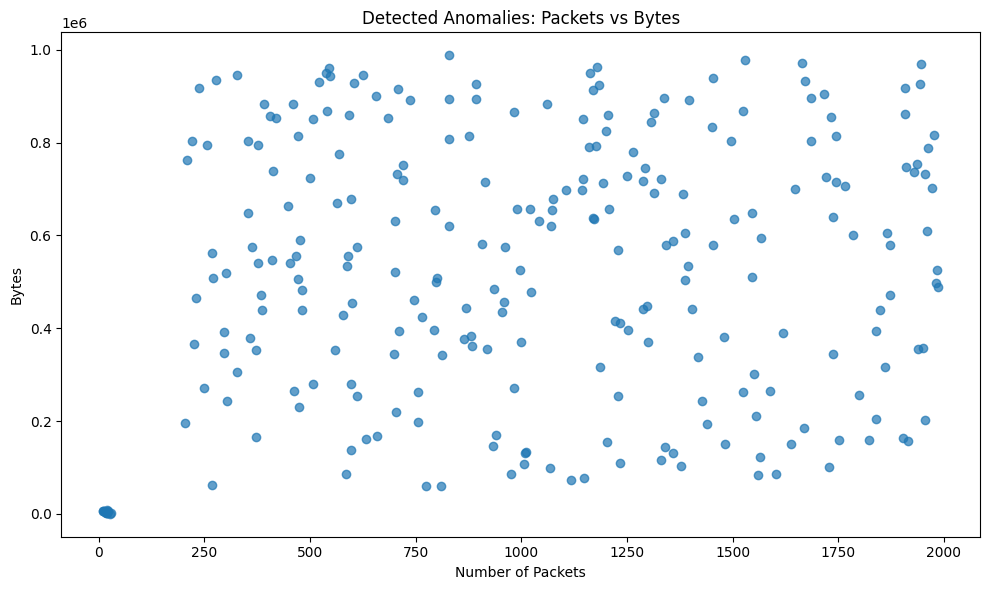

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    anomalies["packets"],
    anomalies["bytes"],
    alpha=0.7)
plt.title("Detected Anomalies: Packets vs Bytes")
plt.xlabel("Number of Packets")
plt.ylabel("Bytes")
plt.tight_layout()
plt.show()

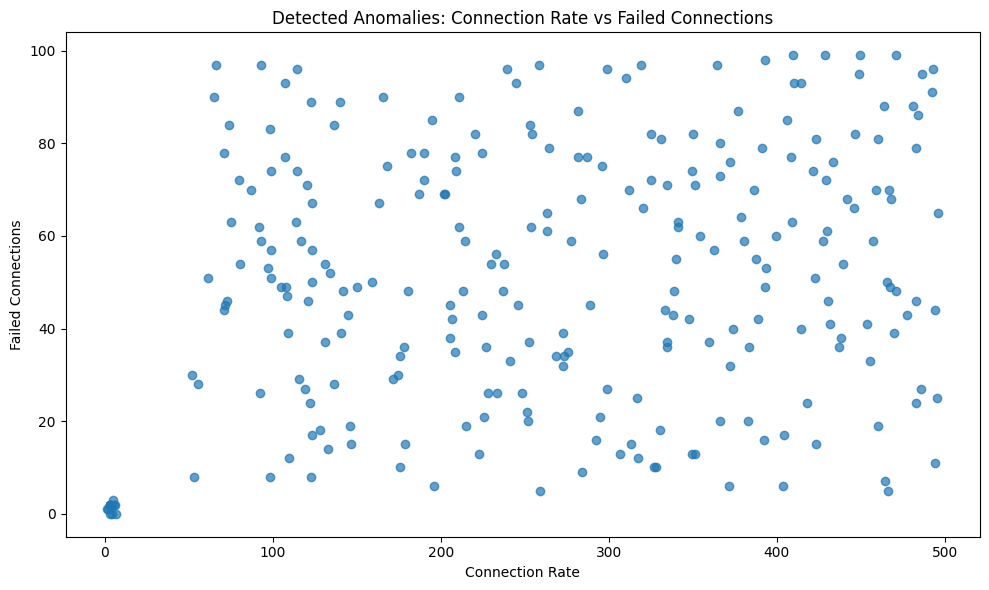

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    anomalies["connection_rate"],
    anomalies["failed_connections"],
    alpha=0.7
)

plt.title("Detected Anomalies: Connection Rate vs Failed Connections")
plt.xlabel("Connection Rate")
plt.ylabel("Failed Connections")

plt.tight_layout()
plt.show()

In [ ]:
# Analyze protocols among detected anomalies

anomaly_protocols = anomalies["protocol"].value_counts()

print("Protocols in Detected Anomalies")
print("=" * 40)
print()

print(anomaly_protocols)

Protocols in Detected Anomalies

protocol
TCP    148
UDP    115
Name: count, dtype: int64


In [ ]:
df["risk_score"] = 0

df.loc[df["anomaly"] == -1, "risk_score"] += 50

df.loc[df["failed_connections"] > 10, "risk_score"] += 20

df.loc[df["connection_rate"] > 50, "risk_score"] += 15

df.loc[df["unusual_port"] == 1, "risk_score"] += 15

df["risk_score"] = df["risk_score"].clip(upper=100)

print("Risk scoring completed successfully!")
print()
print("Risk score statistics:")
print(df["risk_score"].describe())

Risk scoring completed successfully!

Risk score statistics:
count    5250.000000
mean        4.836190
std        21.217061
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       100.000000
Name: risk_score, dtype: float64


In [ ]:
def classify_risk(score):
    if score >= 80:
        return "Critical"
    elif score >= 60:
        return "High"
    elif score >= 30:
        return "Medium"
    else:
        return "Low"

df["risk_level"] = df["risk_score"].apply(classify_risk)

print("Risk classification completed successfully!")
print()
print("Risk level distribution:")
print()
print(df["risk_level"].value_counts())

Risk classification completed successfully!

Risk level distribution:

risk_level
Low         4987
Critical     250
Medium        13
Name: count, dtype: int64


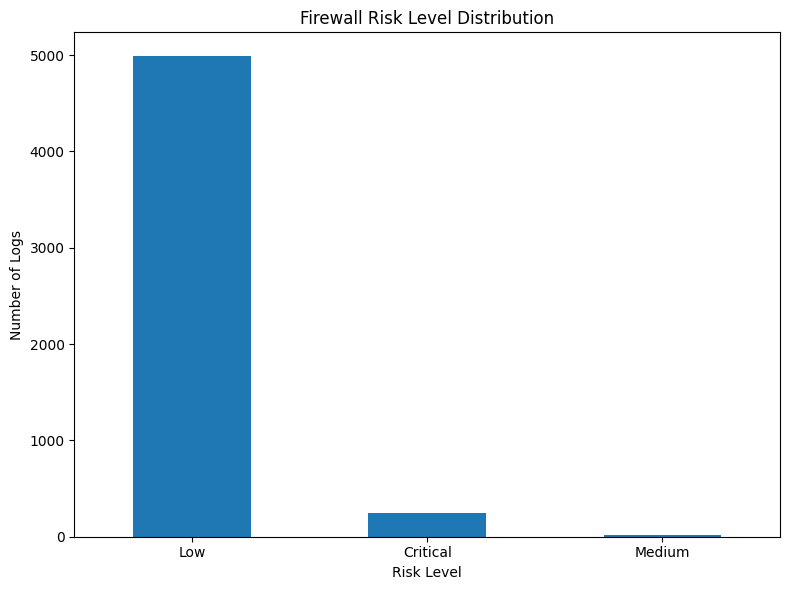

In [ ]:
risk_counts = df["risk_level"].value_counts()
plt.figure(figsize=(8, 6))
risk_counts.plot(
    kind="bar"
)
plt.title("Firewall Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Logs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def generate_alert(row):
    if row["risk_level"] == "Critical":
        return (
            f"CRITICAL ALERT: Suspicious traffic detected "
            f"from {row['src_ip']} to {row['dst_ip']} "
            f"on port {row['dst_port']}."
        )

    elif row["risk_level"] == "High":
        return (
            f"HIGH RISK ALERT: Unusual traffic detected "
            f"from {row['src_ip']} to {row['dst_ip']} "
            f"on port {row['dst_port']}."
        )

    elif row["risk_level"] == "Medium":
        return (
            f"MEDIUM RISK ALERT: Potentially unusual traffic "
            f"detected from {row['src_ip']} to {row['dst_ip']} "
            f"on port {row['dst_port']}."
        )

    else:
        return "No security alert."


df["security_alert"] = df.apply(
    generate_alert,
    axis=1
)

print("Security alert generation completed successfully!")
print()

print("Example security alerts:")
print()

print(
    df[df["risk_level"] != "Low"][
        [
            "timestamp",
            "src_ip",
            "dst_ip",
            "dst_port",
            "risk_score",
            "risk_level",
            "security_alert"
        ]
    ].head(10).to_string(index=False)
)

Security alert generation completed successfully!

Example security alerts:

          timestamp         src_ip          dst_ip  dst_port  risk_score risk_level                                                                                             security_alert
2026-01-01 00:26:00 140.124.177.84   58.220.18.172      3389         100   Critical             CRITICAL ALERT: Suspicious traffic detected from 140.124.177.84 to 58.220.18.172 on port 3389.
2026-01-01 00:29:00  160.101.79.52 206.247.110.166        21         100   Critical              CRITICAL ALERT: Suspicious traffic detected from 160.101.79.52 to 206.247.110.166 on port 21.
2026-01-01 00:31:00 220.30.182.235    128.10.63.94      8080         100   Critical              CRITICAL ALERT: Suspicious traffic detected from 220.30.182.235 to 128.10.63.94 on port 8080.
2026-01-01 01:07:00  10.162.146.53   197.69.48.248      5555         100   Critical              CRITICAL ALERT: Suspicious traffic detected from 10.162.146.53

In [ ]:
def detect_anomaly(
    src_port,
    dst_port,
    protocol,
    duration,
    packets,
    bytes_value,
    failed_connections,
    connection_rate,
    timestamp
):

    new_data = pd.DataFrame({
        "src_port": [src_port],
        "dst_port": [dst_port],
        "duration": [duration],
        "packets": [packets],
        "bytes": [bytes_value],
        "failed_connections": [failed_connections],
        "connection_rate": [connection_rate],
        "hour": [pd.to_datetime(timestamp).hour]
    })

    new_data["bytes_per_packet"] = (
        new_data["bytes"] /
        new_data["packets"].replace(0, 1)
    )

    new_data["packet_rate"] = (
        new_data["packets"] /
        new_data["duration"].replace(0, 1)
    )

    new_data["failed_connection_ratio"] = (
        new_data["failed_connections"] /
        new_data["connection_rate"].replace(0, 1)
    )

    new_data["unusual_port"] = (
        ~new_data["dst_port"].isin(common_ports)
    ).astype(int)

    new_X = new_data[features]

    new_X_scaled = scaler.transform(new_X)

    prediction = model.predict(new_X_scaled)[0]

    if prediction == -1:
        result = "Anomaly"
    else:
        result = "Normal"

    return result


print("Anomaly detection function created successfully!")

Anomaly detection function created successfully!


In [ ]:
normal_result = detect_anomaly(
    src_port=24567,
    dst_port=443,
    protocol="TCP",
    duration=1.8,
    packets=18,
    bytes_value=5200,
    failed_connections=0,
    connection_rate=5.2,
    timestamp="2026-01-10 10:30:00"
)

print("Normal Traffic Test")
print("=" * 30)
print()
print("Prediction:", normal_result)

Normal Traffic Test

Prediction: Normal


In [ ]:
# Test the model with a new suspicious firewall log

suspicious_result = detect_anomaly(
    src_port=52341,
    dst_port=4444,
    protocol="TCP",
    duration=180,
    packets=1200,
    bytes_value=650000,
    failed_connections=65,
    connection_rate=250,
    timestamp="2026-01-10 22:45:00"
)

print("Suspicious Traffic Test")
print("=" * 30)
print()
print("Prediction:", suspicious_result)

Suspicious Traffic Test

Prediction: Anomaly


In [ ]:
# Save the trained model and scaler

import joblib

joblib.dump(model, "firewall_isolation_forest.pkl")
joblib.dump(scaler, "firewall_scaler.pkl")

print("Model and scaler saved successfully!")
print()
print("Saved files:")
print("- firewall_isolation_forest.pkl")
print("- firewall_scaler.pkl")

Model and scaler saved successfully!

Saved files:
- firewall_isolation_forest.pkl
- firewall_scaler.pkl


In [ ]:
# Export the analyzed firewall dataset

output_file = "firewall_anomaly_detection_results.csv"

df.to_csv(
    output_file,
    index=False
)

print("Analyzed firewall dataset exported successfully!")
print()
print("File:", output_file)
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

Analyzed firewall dataset exported successfully!

File: firewall_anomaly_detection_results.csv
Number of records: 5250
Number of columns: 21


In [ ]:
# Final project summary

total_logs = len(df)
normal_logs = (df["anomaly"] == 1).sum()
anomalous_logs = (df["anomaly"] == -1).sum()

critical_logs = (df["risk_level"] == "Critical").sum()
high_logs = (df["risk_level"] == "High").sum()
medium_logs = (df["risk_level"] == "Medium").sum()
low_logs = (df["risk_level"] == "Low").sum()

print("=" * 50)
print("FIREWALL LOG ANOMALY DETECTOR - FINAL RESULTS")
print("=" * 50)
print()
print(f"Total firewall logs       : {total_logs}")
print(f"Normal logs               : {normal_logs}")
print(f"Detected anomalies        : {anomalous_logs}")
print(f"Anomaly percentage        : {(anomalous_logs / total_logs) * 100:.2f}%")
print()
print("Risk Classification")
print("-" * 30)
print(f"Critical                  : {critical_logs}")
print(f"High                      : {high_logs}")
print(f"Medium                    : {medium_logs}")
print(f"Low                       : {low_logs}")
print()
print("Model")
print("-" * 30)
print("Algorithm                 : Isolation Forest")
print("Number of trees           : 200")
print("Contamination             : 5%")
print()
print("Testing")
print("-" * 30)
print("Normal traffic test       : Normal")
print("Suspicious traffic test   : Anomaly")
print()
print("Exported files")
print("-" * 30)
print("firewall_isolation_forest.pkl")
print("firewall_scaler.pkl")
print("firewall_anomaly_detection_results.csv")
print()
print("=" * 50)
print("PROJECT IMPLEMENTATION COMPLETED")
print("=" * 50)

FIREWALL LOG ANOMALY DETECTOR - FINAL RESULTS

Total firewall logs       : 5250
Normal logs               : 4987
Detected anomalies        : 263
Anomaly percentage        : 5.01%

Risk Classification
------------------------------
Critical                  : 250
High                      : 0
Medium                    : 13
Low                       : 4987

Model
------------------------------
Algorithm                 : Isolation Forest
Number of trees           : 200
Contamination             : 5%

Testing
------------------------------
Normal traffic test       : Normal
Suspicious traffic test   : Anomaly

Exported files
------------------------------
firewall_isolation_forest.pkl
firewall_scaler.pkl
firewall_anomaly_detection_results.csv

PROJECT IMPLEMENTATION COMPLETED
